> **Superseded (2026-11-25).** Kept for the record of how the project developed. The current pipeline is `ev_siting_final.ipynb` (EV-registration demand weight, audit fixes, all models and scenarios in one notebook). Numbers here use the earlier population-based weight.

# EV Charging Optimizer (Delhi): Model 1, Grid Baseline

Policy-driven baseline following Vansola et al. (2023) and the ICCT Haryana method (Dash & Anup, 2024).

**Pipeline**
1. Load Delhi wards, clean them into one boundary (close slivers, fill holes), reproject to a metric CRS
2. Load commercial/industrial land use (OSM, cached after the first pull)
3. Load the 3 km grid made in QGIS (2 km for the sensitivity run); a Python fallback builds the same grid if the file is missing
4. Compute the commercial/industrial **area share** of each cell
5. Keep cells whose share meets a threshold (candidate cells)
6. Overlay **existing chargers**: count per cell, flag served cells, distance from each cell centroid to the nearest charger
7. Place one station per candidate cell: centroid, optionally snapped to a feasible site
8. Diagnostics, maps, sensitivity (grid size and threshold), export

**Status:** wired to the real Delhi files. The first run pulls land use from OSM (needs internet) and saves it to `data/delhi_landuse_ci.gpkg`; later runs read that file.

Existing stations are reported alongside the result (`drop_covered=False`) so the grid output stays comparable with K-means and MCLP.

## 0. Imports

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box, Point, Polygon

warnings.filterwarnings("ignore", category=FutureWarning)

## 1. Config and data contract

| Input | Format | Needs |
|---|---|---|
| Ward boundaries | geojson | 273 ward polygons (no land-use field in this file) |
| Land use | `.gpkg` cache written from OSM via `osmnx` | `landuse` field (commercial / retail / industrial) |
| Grid | `.gpkg` from QGIS *Create Grid*, **EPSG:32643**, 3000 m (and 2000 m) | polygons only; do not clip to Delhi |
| Existing chargers | geojson | point layer (1,404 points: SwitchDelhi_Gov + OSM) |
| Feasible sites (optional) | point file | parking lots, fuel stations, commercial plots, etc. |

All geometry work happens in **EPSG:32643 (UTM 43N)** so that distances and areas are in metres.

**Threshold note:** Vansola et al. count grids that *contain* industrial and/or commercial land (91 of 204), so the baseline threshold is a small share (1%). The larger values are run in the sensitivity section.

In [4]:
CFG = dict(
    # --- data ---
    wards_path="data/DELHI Ward Boundaries and Land Use.geojson",
    chargers_path="data/delhi_ev_chargers_master.geojson",
    landuse_cache="data/delhi_landuse_ci.gpkg",       # written on first run, read afterwards
    grid_paths={3: "data/grid_3km.gpkg", 2: "data/grid_2km.gpkg"},   # from QGIS; Python fallback if missing
    feasible_sites_path=None,            # e.g. "data/feasible_sites.geojson"; None = use raw centroids
    osm_place="Delhi, India",

    # --- geometry ---
    crs_metric="EPSG:32643",
    grid_km=3,
    sensitivity_grid_km=2,
    boundary_close_m=300,                # closes slivers between wards, then holes are filled

    # --- candidate rule ---
    # OSM landuse tag -> model category. Residential is deliberately excluded.
    landuse_map={"commercial": "commercial", "retail": "commercial", "industrial": "industrial"},
    area_share_threshold=0.01,           # "contains C/I land" (Vansola et al.); see sensitivity for 5-30%
    min_boundary_overlap=1e-7,           # any overlap (replicates Vansola's 204 grids); 0.5 drops edge cells

    # --- existing stations ---
    drop_covered=False,                  # False: keep all candidates and flag the served ones

    # --- placement ---
    snap_tolerance_m=500,                # max distance to move a centroid to a feasible site
)

## 2. Data loading

The ward file's `districtname` / `ulbname` columns are not reliable (every row says South Delhi / MCD), so only the geometry is used. Dissolving the wards leaves thousands of sliver holes and gaps (e.g. NDMC area), so the boundary is closed and its holes filled.

In [5]:
def union(gs):
    """Union of a GeoSeries (works on old and new GeoPandas)."""
    return gs.union_all() if hasattr(gs, "union_all") else gs.unary_union


def load_boundary(path, crs, close_m=300):
    """Dissolve wards into one polygon, close slivers, fill interior holes."""
    w = gpd.read_file(path).to_crs(crs)
    b = union(w.geometry).buffer(close_m).buffer(-close_m)
    parts = list(getattr(b, "geoms", [b]))
    b = union(gpd.GeoSeries([Polygon(p.exterior) for p in parts], crs=crs))
    return gpd.GeoDataFrame(geometry=[b], crs=crs)


def load_landuse(cache_path, place, landuse_map, crs):
    """Read cached OSM land use; on first run pull it with osmnx and cache it."""
    if not os.path.exists(cache_path):
        import osmnx as ox
        print("No cache found, pulling land use from OSM (can take a minute or two)...")
        raw = ox.features_from_place(place, {"landuse": list(landuse_map)})
        raw = raw[raw.geometry.type.isin(["Polygon", "MultiPolygon"])][["landuse", "geometry"]]
        os.makedirs(os.path.dirname(cache_path) or ".", exist_ok=True)
        raw.reset_index(drop=True).to_file(cache_path, driver="GPKG")
    gdf = gpd.read_file(cache_path)
    gdf = gdf[gdf["landuse"].isin(landuse_map)].copy()
    gdf["lu_class"] = gdf["landuse"].map(landuse_map)
    gdf = gdf.to_crs(crs)
    gdf["geometry"] = gdf.geometry.buffer(0)               # repair invalid rings
    return gdf[["lu_class", "geometry"]].reset_index(drop=True)


def load_points(path, crs):
    return gpd.read_file(path).to_crs(crs)[["geometry"]].reset_index(drop=True)


boundary = load_boundary(CFG["wards_path"], CFG["crs_metric"], CFG["boundary_close_m"])
landuse = load_landuse(CFG["landuse_cache"], CFG["osm_place"], CFG["landuse_map"], CFG["crs_metric"])
existing = load_points(CFG["chargers_path"], CFG["crs_metric"])
feasible = load_points(CFG["feasible_sites_path"], CFG["crs_metric"]) if CFG["feasible_sites_path"] else None

b_poly = boundary.geometry.iloc[0]
print(f"Boundary area: {b_poly.area / 1e6:,.0f} km2 (official Delhi ~1,483 km2) | "
      f"holes left: {sum(len(p.interiors) for p in getattr(b_poly, 'geoms', [b_poly]))}")
print(f"Land-use polygons: {len(landuse)}")
print(landuse.assign(area_km2=landuse.area / 1e6).groupby("lu_class")["area_km2"].agg(["count", "sum"]).round(2))
inside = existing.within(b_poly).sum()
print(f"Existing chargers: {len(existing)} | inside cleaned boundary: {inside} | outside: {len(existing) - inside}")
print(f"Feasible sites: {0 if feasible is None else len(feasible)}")

Boundary area: 1,467 km2 (official Delhi ~1,483 km2) | holes left: 0
Land-use polygons: 725
            count    sum
lu_class                
commercial    494  15.32
industrial    231  66.15
Existing chargers: 1404 | inside cleaned boundary: 1367 | outside: 37
Feasible sites: 0


## 3. Grid

The grid comes from QGIS (*Create Grid*, rectangle, EPSG:32643, extent from the reprojected ward layer). Cells are kept if enough of their area falls inside Delhi, and `area_in_boundary` is stored so that edge cells are not penalised in the share calculation.

If a grid file is missing, `build_grid` makes the same grid in Python (anchored at the lower-left corner of the boundary bounding box).

In [6]:
def build_grid(boundary, cell_m):
    """Python fallback: square cells anchored at the bbox lower-left corner (same as QGIS with extent = layer)."""
    minx, miny, maxx, maxy = boundary.total_bounds
    xs = np.arange(minx, maxx, cell_m)
    ys = np.arange(miny, maxy, cell_m)
    return gpd.GeoDataFrame(geometry=[box(x, y, x + cell_m, y + cell_m) for x in xs for y in ys], crs=boundary.crs)


def get_grid(km, boundary, min_overlap, paths):
    cell_m = km * 1000
    path = paths.get(km)
    if path and os.path.exists(path):
        g = gpd.read_file(path).to_crs(boundary.crs)[["geometry"]].reset_index(drop=True)
        src = "QGIS file"
    else:
        g = build_grid(boundary, cell_m)
        src = "Python fallback"
    g["cell_id"] = np.arange(len(g))
    g["area_in_boundary"] = g.geometry.intersection(boundary.geometry.iloc[0]).area
    g = g[g["area_in_boundary"] / g.geometry.area >= min_overlap].reset_index(drop=True)
    print(f"{km} km grid ({src}): {len(g)} cells kept")
    return g

## 4. Candidate cells by area share

For each cell: (commercial + industrial area inside the cell) / (cell area inside Delhi).

Land-use polygons are unioned before intersecting so overlapping polygons are not double-counted. The per-class shares are kept for reference.

In [7]:
def compute_landuse_share(grid, landuse):
    out = grid.copy()
    all_union = union(landuse.geometry)
    out["share_ci"] = out.geometry.intersection(all_union).area / out["area_in_boundary"]
    for cls, g in landuse.dissolve(by="lu_class").geometry.items():
        out[f"share_{cls}"] = out.geometry.intersection(g).area / out["area_in_boundary"]
    return out


def select_candidates(grid_shares, threshold):
    return grid_shares[grid_shares["share_ci"] >= threshold].copy()

## 5. Existing stations

Per cell: number of existing chargers inside it. A candidate cell is **already served** if it holds at least one (the ICCT/Haryana "one charger per 3 km section" logic). Also stored: the distance from each cell centroid to the nearest existing charger, the Haryana study's accessibility measure.

In [8]:
def add_existing(grid, existing):
    """Add n_existing (chargers inside the cell) and dist_nearest_existing_m (centroid to nearest charger)."""
    out = grid.copy()
    j = gpd.sjoin(existing[["geometry"]], out[["cell_id", "geometry"]], how="inner", predicate="intersects")
    j = j[~j.index.duplicated(keep="first")]                       # a point on a shared edge counts once
    counts = j.groupby("cell_id").size()
    out["n_existing"] = out["cell_id"].map(counts).fillna(0).astype(int)

    cen = gpd.GeoDataFrame(out[["cell_id"]], geometry=out.geometry.centroid, crs=out.crs)
    nn = gpd.sjoin_nearest(cen, existing[["geometry"]], how="left", distance_col="d")
    nn = nn[~nn.index.duplicated(keep="first")]
    out["dist_nearest_existing_m"] = nn["d"].reindex(out.index).values
    return out

## 6. Station placement

Default: the **cell centroid**. If a feasible-sites layer is supplied, the centroid is moved to the nearest feasible site within `snap_tolerance_m`. Cells with no feasible site in range keep the raw centroid and are flagged `snapped = False`.

In [9]:
def place_stations(cands, feasible=None, tol_m=500):
    keep = [c for c in ["cell_id", "share_ci", "n_existing", "already_served"] if c in cands.columns]
    stations = gpd.GeoDataFrame(
        cands[keep].reset_index(drop=True),
        geometry=cands.geometry.centroid.reset_index(drop=True),
        crs=cands.crs,
    )
    stations["snapped"] = False
    stations["snap_dist_m"] = 0.0

    if feasible is None or len(feasible) == 0 or len(stations) == 0:
        return stations

    j = gpd.sjoin_nearest(stations[["geometry"]], feasible[["geometry"]], how="left",
                          max_distance=tol_m, distance_col="d")
    j = j[~j.index.duplicated(keep="first")]
    hit = j["index_right"].notna()

    new_geom = stations.geometry.copy()
    new_geom.loc[hit[hit].index] = feasible.geometry.loc[j.loc[hit, "index_right"].astype(int)].values
    stations = stations.set_geometry(new_geom)
    stations.loc[hit, "snapped"] = True
    stations.loc[hit, "snap_dist_m"] = j.loc[hit, "d"].values
    return stations

## 7. Model runner

In [10]:
def run_grid_model(boundary, landuse, cell_km, threshold, min_overlap, feasible=None, tol_m=500,
                   existing=None, drop_covered=False, grid_paths=None):
    grid = get_grid(cell_km, boundary, min_overlap, grid_paths or {})
    grid = compute_landuse_share(grid, landuse)
    if existing is not None and len(existing) > 0:
        grid = add_existing(grid, existing)
    cands = select_candidates(grid, threshold)

    if "n_existing" in cands.columns:
        cands["already_served"] = cands["n_existing"] >= 1
        if drop_covered:                                   # gap-filling mode: only unserved cells
            cands = cands[~cands["already_served"]].copy()

    stations = place_stations(cands, feasible, tol_m)
    return dict(km=cell_km, threshold=threshold, grid=grid, cands=cands, stations=stations)


def summarise(res, boundary):
    a_km2 = boundary.area.iloc[0] / 1e6
    n = len(res["stations"])
    row = {
        "grid_km": res["km"],
        "threshold": res["threshold"],
        "cells_total": len(res["grid"]),
        "cells_candidate": len(res["cands"]),
        "pct_candidate": round(100 * len(res["cands"]) / len(res["grid"]), 1),
        "stations": n,
        "stations_per_100km2": round(100 * n / a_km2, 2),
        "pct_snapped": round(100 * res["stations"]["snapped"].mean(), 1) if n else np.nan,
    }
    if "already_served" in res["cands"].columns:
        served = int(res["cands"]["already_served"].sum())
        row.update({
            "cands_already_served": served,
            "cands_need_new": len(res["cands"]) - served,
            "pct_cells_with_charger": round(100 * (res["grid"]["n_existing"] >= 1).mean(), 1),
            "mean_dist_to_charger_km": round(res["grid"]["dist_nearest_existing_m"].mean() / 1000, 2),
            "median_dist_to_charger_km": round(res["grid"]["dist_nearest_existing_m"].median() / 1000, 2),
        })
    return row

## 8. Run the 3 km baseline

In [11]:
RUN_ARGS = dict(feasible=feasible, tol_m=CFG["snap_tolerance_m"], existing=existing,
                drop_covered=CFG["drop_covered"], grid_paths=CFG["grid_paths"])

base = run_grid_model(boundary, landuse, CFG["grid_km"], CFG["area_share_threshold"],
                      CFG["min_boundary_overlap"], **RUN_ARGS)
pd.DataFrame([summarise(base, boundary)]).T

3 km grid (QGIS file): 205 cells kept


,0
grid_km,3.00
threshold,0.01
cells_total,205.00
cells_candidate,102.00
pct_candidate,49.80
stations,102.00
stations_per_100km2,6.95
pct_snapped,0.00
cands_already_served,89.00
cands_need_new,13.00


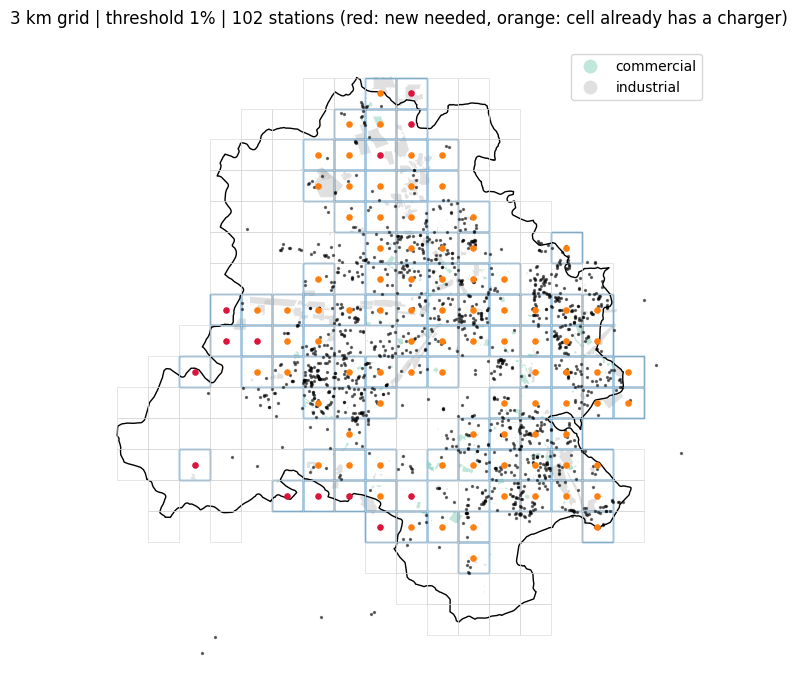

In [12]:
def plot_result(res, boundary, landuse, existing=None, title=None):
    fig, ax = plt.subplots(figsize=(8, 9))
    boundary.boundary.plot(ax=ax, color="black", linewidth=1)
    res["grid"].boundary.plot(ax=ax, color="lightgrey", linewidth=0.4)
    landuse.plot(ax=ax, column="lu_class", alpha=0.4, legend=True, cmap="Set2")
    res["cands"].plot(ax=ax, facecolor="none", edgecolor="tab:blue", linewidth=1)
    if existing is not None:
        existing.plot(ax=ax, color="black", markersize=2, alpha=0.5, zorder=4)
    st = res["stations"]
    if "already_served" in st.columns:
        st[st["already_served"]].plot(ax=ax, color="tab:orange", markersize=14, zorder=5)
        st[~st["already_served"]].plot(ax=ax, color="crimson", markersize=14, zorder=6)
    else:
        st.plot(ax=ax, color="crimson", markersize=12, zorder=5)
    ax.set_title(title or f"{res['km']} km grid | threshold {res['threshold']:.0%} | "
                          f"{len(st)} stations (red: new needed, orange: cell already has a charger)")
    ax.set_axis_off()
    plt.show()

plot_result(base, boundary, landuse, existing)

## 9. Sensitivity

**9a. Grid size (3 km vs 2 km).** Same code, one parameter changed. Besides counts, we compare spatial agreement: for each 3 km station, the distance to the nearest 2 km station.

In [13]:
alt = run_grid_model(boundary, landuse, CFG["sensitivity_grid_km"], CFG["area_share_threshold"],
                     CFG["min_boundary_overlap"], **RUN_ARGS)

pd.DataFrame([summarise(base, boundary), summarise(alt, boundary)])

2 km grid (QGIS file): 431 cells kept


,grid_km,threshold,cells_total,cells_candidate,pct_candidate,stations,stations_per_100km2,pct_snapped,cands_already_served,cands_need_new,pct_cells_with_charger,mean_dist_to_charger_km,median_dist_to_charger_km
0,3,0.01,205,102,49.8,102,6.95,0.0,89,13,62.9,1.89,1.09
1,2,0.01,431,165,38.3,165,11.25,0.0,132,33,54.1,1.74,1.05


Distance from each 3 km station to nearest 2 km station (m):
count     116.0
mean     1096.0
std       444.0
min       707.0
25%       707.0
50%       707.0
75%      1581.0
max      2121.0
Name: nn_dist_m, dtype: float64


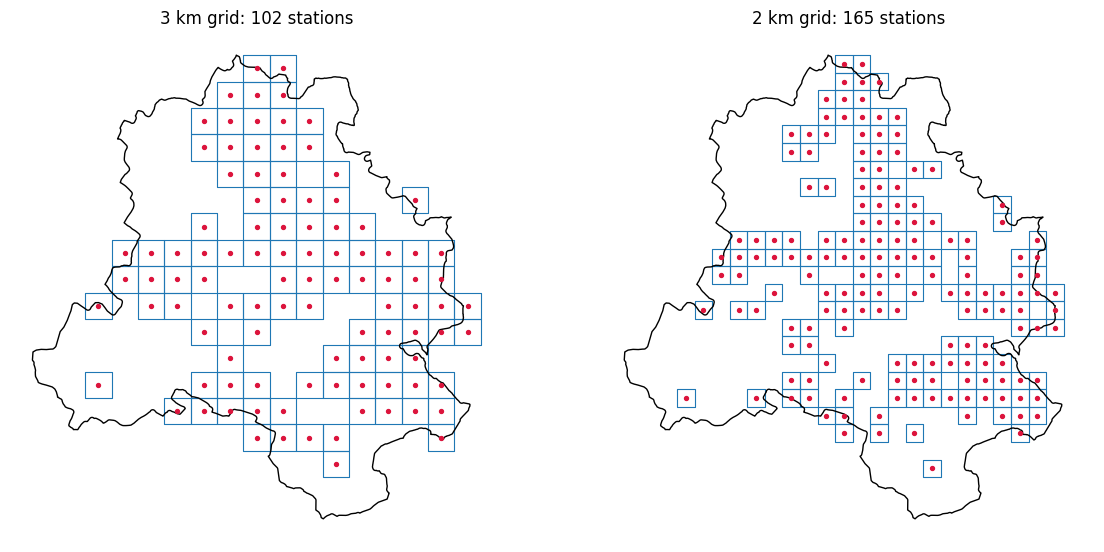

In [14]:
d = gpd.sjoin_nearest(base["stations"][["geometry"]], alt["stations"][["geometry"]],
                      how="left", distance_col="nn_dist_m")["nn_dist_m"]
print(f"Distance from each {base['km']} km station to nearest {alt['km']} km station (m):")
print(d.describe().round(0))

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
for ax, res in zip(axes, [base, alt]):
    boundary.boundary.plot(ax=ax, color="black", linewidth=1)
    res["cands"].plot(ax=ax, facecolor="none", edgecolor="tab:blue", linewidth=0.8)
    res["stations"].plot(ax=ax, color="crimson", markersize=8, zorder=5)
    ax.set_title(f"{res['km']} km grid: {len(res['stations'])} stations")
    ax.set_axis_off()
plt.show()

**9b. Area-share threshold.** How much the result depends on the threshold (1% is the "contains C/I land" replication of Vansola et al.).

In [15]:
rows = []
for thr in [0.01, 0.05, 0.10, 0.20, 0.30]:
    for km in [CFG["grid_km"], CFG["sensitivity_grid_km"]]:
        r = run_grid_model(boundary, landuse, km, thr, CFG["min_boundary_overlap"], **RUN_ARGS)
        rows.append(summarise(r, boundary))
sens = pd.DataFrame(rows)
sens

3 km grid (QGIS file): 205 cells kept
2 km grid (QGIS file): 431 cells kept
3 km grid (QGIS file): 205 cells kept
2 km grid (QGIS file): 431 cells kept
3 km grid (QGIS file): 205 cells kept
2 km grid (QGIS file): 431 cells kept
3 km grid (QGIS file): 205 cells kept
2 km grid (QGIS file): 431 cells kept
3 km grid (QGIS file): 205 cells kept
2 km grid (QGIS file): 431 cells kept


,grid_km,threshold,cells_total,cells_candidate,pct_candidate,stations,stations_per_100km2,pct_snapped,cands_already_served,cands_need_new,pct_cells_with_charger,mean_dist_to_charger_km,median_dist_to_charger_km
0,3,0.01,205,102,49.8,102,6.95,0.0,89,13,62.9,1.89,1.09
1,2,0.01,431,165,38.3,165,11.25,0.0,132,33,54.1,1.74,1.05
2,3,0.05,205,52,25.4,52,3.55,0.0,45,7,62.9,1.89,1.09
3,2,0.05,431,104,24.1,104,7.09,0.0,80,24,54.1,1.74,1.05
4,3,0.10,205,34,16.6,34,2.32,0.0,29,5,62.9,1.89,1.09
5,2,0.10,431,69,16.0,69,4.70,0.0,52,17,54.1,1.74,1.05
6,3,0.20,205,19,9.3,19,1.30,0.0,16,3,62.9,1.89,1.09
7,2,0.20,431,38,8.8,38,2.59,0.0,25,13,54.1,1.74,1.05
8,3,0.30,205,11,5.4,11,0.75,0.0,9,2,62.9,1.89,1.09
9,2,0.30,431,20,4.6,20,1.36,0.0,11,9,54.1,1.74,1.05


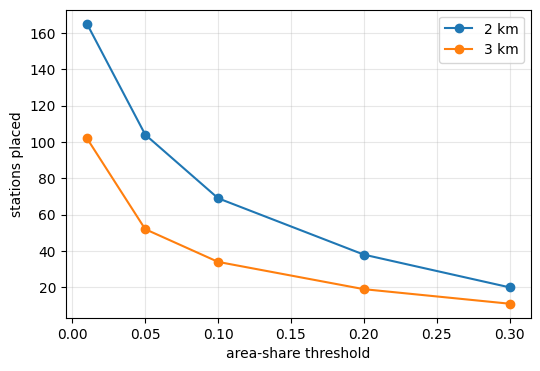

In [16]:
fig, ax = plt.subplots(figsize=(6, 4))
for km, g in sens.groupby("grid_km"):
    ax.plot(g["threshold"], g["stations"], marker="o", label=f"{km} km")
ax.set_xlabel("area-share threshold"); ax.set_ylabel("stations placed"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 10. Export

In [ ]:
os.makedirs("outputs", exist_ok=True)

out = base["stations"].to_crs("EPSG:4326")
out["lon"], out["lat"] = out.geometry.x, out.geometry.y
out.drop(columns="geometry").to_csv(f"outputs/grid_{CFG['grid_km']}km_stations.csv", index=False)
out.to_file(f"outputs/grid_{CFG['grid_km']}km_stations.geojson", driver="GeoJSON")

base["grid"].to_crs("EPSG:4326").to_file(f"outputs/grid_{CFG['grid_km']}km_cells.geojson", driver="GeoJSON")
sens.to_csv("outputs/grid_sensitivity.csv", index=False)
print("Saved to outputs/")

## Open items before final runs

- [ ] Run once with internet so the OSM land-use cache is written; check the printed class counts and areas. OSM coverage in Delhi is patchy, so consider supplementing with `building=commercial/industrial/retail/warehouse` footprints
- [ ] Compare `cells_total` and `cells_candidate` (3 km, threshold 1%, any overlap) against Vansola et al. (204 grids, 91 candidates) and note the gap in the report
- [ ] Confirm the SwitchDelhi_Gov points are public four-wheeler-capable stations (scope is 4W only)
- [ ] Check why the ward file leaves NDMC / Cantonment gaps and whether the filled boundary is acceptable
- [ ] Decide the feasible-sites layer for the "nudge" step (or run on raw centroids)
- [ ] Decide with the team whether the final comparison uses `drop_covered=False` (baseline) or `True` (gap-filling)
- [ ] Optional demand weighting, to contrast with the K-means and MCLP models